# Does boosting find nonlinear signal beyond a linear model? Forecasting next-year stock returns from fundamentals

**Question.** Using a company's financial statements for year *Y*, can we rank stocks by their return over year *Y+1*, and does a gradient-boosted model add anything *beyond* what a simple linear model already captures?

**Design choices, and why**

1. **Target = next-year return, ranked within each year.** Market-wide moves and inflation-like drift hit every stock in a year at once, so they cannot be predicted from company-level features. Ranking each stock against the others *in the same year* removes them exactly (the median return swings from -13% to +18% across years, shown below) and also tames the extreme outliers in raw returns (the maximum is 2.4 million percent).
2. **Features ranked within year too**, so nominal scale and inflation drop out of revenue, assets, and similar level variables.
3. **Two-stage model.** (a) A ridge regression finds the *linear* cross-sectional signal. (b) Gradient boosting is trained only on the ridge's **out-of-fold residuals**, so it can only be rewarded for structure the linear model missed. If it adds nothing, that is a finding.
4. **Walk-forward evaluation.** Train on earlier years, test on the next one (2016, 2017, 2018), so there is never any peeking at the future. All hyperparameters are chosen on training years only.
5. **Metric = rank information coefficient (IC):** the Spearman correlation between predicted and realized return rank within a test year. This is the standard measure for cross-sectional return forecasts.

In [1]:
import glob, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)
rng = np.random.default_rng(0)

## 1. Data: features at year *Y*, return over year *Y+1*

In [2]:
frames = []
for f in sorted(Path("Data").glob("*_Financial_Data.csv")):
    year = int(re.match(r"(\d{4})_", f.name).group(1))
    d = pd.read_csv(f).rename(columns={"Unnamed: 0": "ticker"})
    # each file carries the *following* year's price change; keep it as the forward return
    d = pd.concat([d.drop(columns=[f"{year+1} PRICE VAR [%]"]),
                   pd.DataFrame({"year": year, "fwd_ret": d[f"{year+1} PRICE VAR [%]"]})], axis=1)
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
df = df[df.fwd_ret.notna()].reset_index(drop=True)

# 'Class' is just the sign of the forward return, so it must never be a feature
NON_FEATURES = ["ticker", "year", "fwd_ret", "Class", "Sector"]
feat = [c for c in df.columns if c not in NON_FEATURES and pd.api.types.is_numeric_dtype(df[c])]
feat = [c for c in feat if df[c].notna().mean() > 0.5 and df[c].nunique() > 5]
print(f"{len(df):,} company-years, {df.ticker.nunique():,} tickers, {len(feat)} numeric features")
print(df.groupby("year").size().rename("companies per year").to_string())

22,077 company-years, 4,980 tickers, 218 numeric features
year
2014    3808
2015    4120
2016    4797
2017    4960
2018    4392


### The market-wide move is large, and it differs every year

A model fit on raw returns would partly try to learn "which year is it", which no company-level feature can tell it. Ranking within year removes that component by construction.

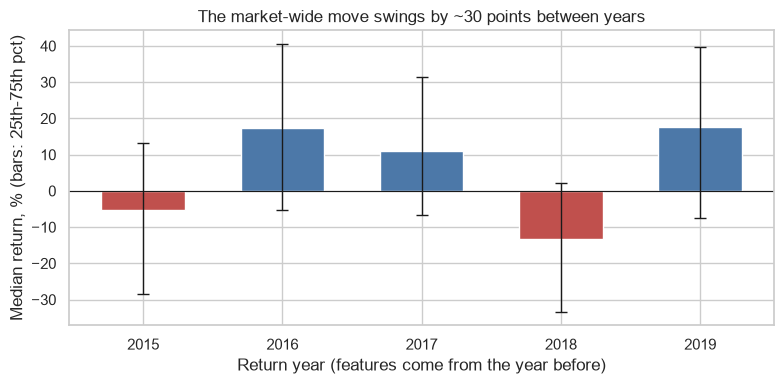

      median   p25   p75
year                    
2014    -5.3 -28.6  13.3
2015    17.3  -5.2  40.6
2016    10.9  -6.7  31.6
2017   -13.3 -33.4   2.1
2018    17.6  -7.5  39.6


In [3]:
g = df.groupby("year").fwd_ret
q = pd.DataFrame({"median": g.median(), "p25": g.quantile(.25), "p75": g.quantile(.75)})
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(q.index + 1, q["median"], color=np.where(q["median"] > 0, "#4c78a8", "#c0504d"), width=.6)
ax.errorbar(q.index + 1, q["median"], yerr=[q["median"] - q.p25, q.p75 - q["median"]],
            fmt="none", ecolor="k", capsize=4, lw=1)
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("Return year (features come from the year before)")
ax.set_ylabel("Median return, % (bars: 25th-75th pct)")
ax.set_title("The market-wide move swings by ~30 points between years")
plt.tight_layout(); plt.savefig("figures/01_market_wide_moves.png", dpi=150); plt.show()
print(q.round(1).to_string())

## 2. Remove market-wide effects: rank within year

In [4]:
# features: within-year percentile rank (missing -> 0.5, the median rank); sector as dummies
X = df.groupby("year")[feat].rank(pct=True).fillna(0.5)
X = pd.concat([X, pd.get_dummies(df["Sector"], dtype=float)], axis=1)
# target: within-year percentile rank of the forward return, centred at 0
df["y"] = df.groupby("year")["fwd_ret"].rank(pct=True) - 0.5
df["mcap_pct"] = df.groupby("year")["Market Cap"].rank(pct=True)
Xv, yv, gv = X.values, df["y"].values, df["year"].values
years = sorted(df.year.unique())
print("feature matrix:", Xv.shape, "| target is uniform on [-0.5, 0.5] in every year")

feature matrix: (22077, 229) | target is uniform on [-0.5, 0.5] in every year


## 3. Walk-forward models

* **Ridge** - penalty strength chosen by leave-one-year-out IC *inside the training years*.
* **Ridge residuals** - ridge predictions for the training years come from models that never saw that year (leave-one-year-out), so the boosting stage learns from honest residuals, not from a linear fit that has already memorised its own training data.
* **Boosting** - deliberately small and heavily regularised (depth 3, slow learning rate, large leaf minimum). The number of trees is chosen by early stopping on the last training year.
* **Three predictors compared:** ridge alone, boosting alone on the target, and **ridge + boosting-on-residuals**.

In [5]:
def ic(pred, truth):
    return spearmanr(pred, truth)[0]

def ridge_oof(Xtr, ytr, gtr, alpha):
    """leave-one-year-out ridge predictions for the training years"""
    oof = np.zeros(len(ytr))
    for g in np.unique(gtr):
        m = gtr == g
        oof[m] = Ridge(alpha=alpha).fit(Xtr[~m], ytr[~m]).predict(Xtr[m])
    return oof

def pick_alpha(Xtr, ytr, gtr, grid=(1e2, 1e3, 1e4, 3e4, 1e5, 3e5, 1e6)):
    def score(a):
        oof = ridge_oof(Xtr, ytr, gtr, a)
        return np.mean([ic(oof[gtr == g], ytr[gtr == g]) for g in np.unique(gtr)])
    return max(grid, key=score)

GBM = dict(max_depth=3, learning_rate=0.03, subsample=0.7, colsample_bytree=0.5,
           min_child_weight=50, reg_lambda=10, n_jobs=4, random_state=0)

def pick_trees(Xtr, target, gtr, max_trees=600):
    """early stopping on the most recent training year"""
    val = gtr == gtr.max()
    m = XGBRegressor(n_estimators=max_trees, early_stopping_rounds=40, **GBM)
    m.fit(Xtr[~val], target[~val], eval_set=[(Xtr[val], target[val])], verbose=False)
    return max(int(m.best_iteration) + 1, 20)

preds, info, last_model = [], [], None
for ty in years[2:]:                       # test on 2016, 2017, 2018
    tr, te = gv < ty, gv == ty
    Xtr, ytr, gtr, Xte = Xv[tr], yv[tr], gv[tr], Xv[te]
    alpha = pick_alpha(Xtr, ytr, gtr)
    p_ridge = Ridge(alpha=alpha).fit(Xtr, ytr).predict(Xte)
    resid = ytr - ridge_oof(Xtr, ytr, gtr, alpha)
    n_res = pick_trees(Xtr, resid, gtr)
    boost_res = XGBRegressor(n_estimators=n_res, **GBM).fit(Xtr, resid)
    p_res = boost_res.predict(Xte)
    n_raw = pick_trees(Xtr, ytr, gtr)
    p_gbm = XGBRegressor(n_estimators=n_raw, **GBM).fit(Xtr, ytr).predict(Xte)
    # control: a *linear* second stage on the same residuals (its own penalty, chosen the same way)
    alpha2 = pick_alpha(Xtr, resid, gtr)
    p_lin2 = Ridge(alpha=alpha2).fit(Xtr, resid).predict(Xte)
    out = df.loc[te, ["year", "ticker", "y", "fwd_ret", "mcap_pct", "EPS"]].copy()
    out["p_ridge"], out["p_gbm"], out["p_res"], out["p_stack"] = p_ridge, p_gbm, p_res, p_ridge + p_res
    out["p_lin2"] = p_lin2
    preds.append(out)
    info.append(dict(test_year=ty, train_years=len(np.unique(gtr)), ridge_alpha=alpha,
                     trees_residual_model=n_res, trees_standalone_model=n_raw, second_stage_alpha=alpha2))
    last_model = boost_res
P = pd.concat(preds, ignore_index=True)
print(pd.DataFrame(info).to_string(index=False))

 test_year  train_years  ridge_alpha  trees_residual_model  trees_standalone_model  second_stage_alpha
      2016            2    1000000.0                    22                      29           1000000.0
      2017            3    1000000.0                    20                      20           1000000.0
      2018            4      10000.0                   155                     300               100.0


## 4. Results

Rank IC by test year (return year = test year + 1)
      Ridge (linear)  Boosting alone  Ridge + boosting on residuals
year                                                               
2016           0.135           0.083                          0.092
2017           0.173           0.184                          0.187
2018           0.243           0.252                          0.260
mean           0.184           0.173                          0.180


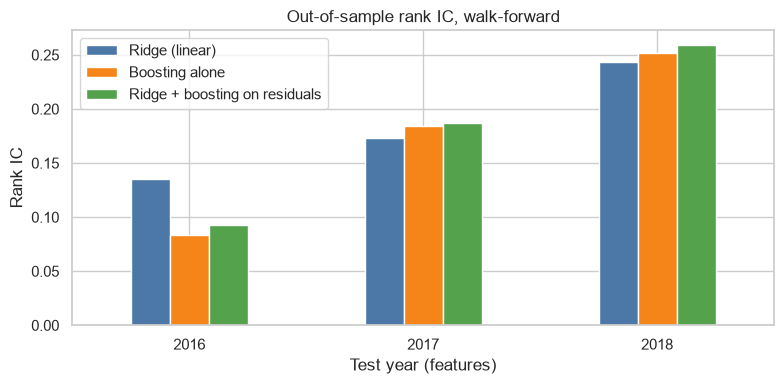

In [6]:
models = {"Ridge (linear)": "p_ridge", "Boosting alone": "p_gbm", "Ridge + boosting on residuals": "p_stack"}
res = pd.DataFrame({name: P.groupby("year").apply(lambda d: ic(d[c], d["y"])) for name, c in models.items()})
res.loc["mean"] = res.mean()
print("Rank IC by test year (return year = test year + 1)"); print(res.round(3).to_string())

ax = res.drop(index="mean").plot.bar(figsize=(8, 4), rot=0, color=["#4c78a8", "#f58518", "#54a24b"])
ax.set_xlabel("Test year (features)"); ax.set_ylabel("Rank IC")
ax.set_title("Out-of-sample rank IC, walk-forward")
plt.tight_layout(); plt.savefig("figures/02_ic_by_model.png", dpi=150); plt.show()

### Does boosting add anything *beyond* the linear model?

The direct test: correlate the boosting model's output with what the ridge got **wrong** (the realized residual `y - ridge prediction`) on the held-out year. Confidence intervals come from resampling companies.

In [7]:
rows = []
for yr, d in P.groupby("year"):
    resid = (d["y"] - d["p_ridge"]).values
    row = dict(test_year=yr)
    for name, col in [("boosting", "p_res"), ("linear 2nd stage", "p_lin2")]:
        boot = []
        for _ in range(500):
            i = rng.integers(0, len(d), len(d))
            boot.append(ic(d[col].values[i], resid[i]))
        row[name] = ic(d[col], resid)
        row[name + " 95% CI"] = f"[{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]"
    rows.append(row)
inc = pd.DataFrame(rows)
print(inc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print()
print("Ridge IC vs ridge + boosting IC vs ridge + linear 2nd stage IC (mean over test years):")
print(P.groupby("year").apply(lambda d: pd.Series({
    "ridge": ic(d.p_ridge, d.y), "ridge+boosting": ic(d.p_stack, d.y),
    "ridge+linear 2nd stage": ic(d.p_ridge + d.p_lin2, d.y)})).mean().round(3).to_string())

 test_year  boosting boosting 95% CI  linear 2nd stage linear 2nd stage 95% CI
      2016     0.083  [0.049, 0.113]             0.131          [0.102, 0.163]
      2017     0.182  [0.154, 0.208]             0.169          [0.138, 0.196]
      2018     0.142  [0.111, 0.172]             0.073          [0.040, 0.100]

Ridge IC vs ridge + boosting IC vs ridge + linear 2nd stage IC (mean over test years):
ridge                     0.184
ridge+boosting            0.180
ridge+linear 2nd stage    0.175


### Where does the signal live? Segment by size and profitability

small                   0.298
mid                     0.044
large                   0.091
EPS <= 0                0.243
EPS > 0                 0.071
excl. smallest third    0.072

Top-minus-bottom predicted quintile, median next-year return (percentage points):
      all stocks  excl. smallest third
year                                  
2016        14.1                  -0.6
2017        24.2                   8.8
2018        39.0                  17.1


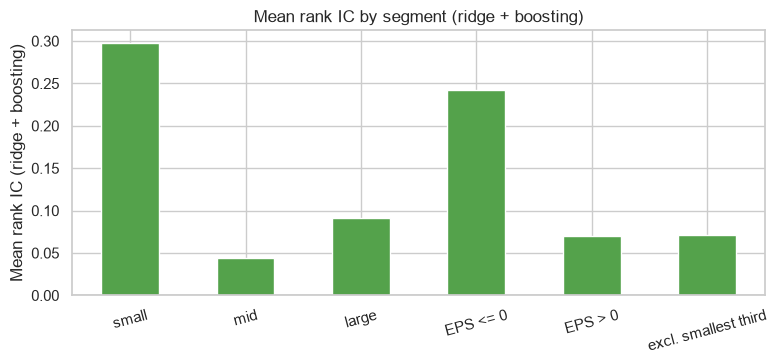

In [8]:
P["size"] = pd.cut(P["mcap_pct"], [0, 1/3, 2/3, 1], labels=["small", "mid", "large"], include_lowest=True)
P["profit"] = np.where(P["EPS"] > 0, "EPS > 0", "EPS <= 0")
def seg_ic(col):
    rows = {}
    for lab, d in P.groupby(col):
        per_year = [ic(x["p_stack"], x["y"]) for _, x in d.groupby("year") if len(x) > 100]
        rows[lab] = np.mean(per_year)
    return pd.Series(rows)
seg = pd.concat([seg_ic("size"), seg_ic("profit")])
big = P[P.mcap_pct > 1/3]
seg["excl. smallest third"] = np.mean([ic(x.p_stack, x.y) for _, x in big.groupby("year")])
print(seg.round(3).to_string())

def quintile_spread(d):
    q = pd.qcut(d.p_stack.rank(method="first"), 5, labels=False)
    return d.fwd_ret[q == 4].median() - d.fwd_ret[q == 0].median()
sp = pd.DataFrame({"all stocks": P.groupby("year").apply(quintile_spread),
                   "excl. smallest third": big.groupby("year").apply(quintile_spread)})
print("\nTop-minus-bottom predicted quintile, median next-year return (percentage points):")
print(sp.round(1).to_string())
ax = seg.plot.bar(figsize=(8, 3.8), rot=15, color="#54a24b")
ax.set_ylabel("Mean rank IC (ridge + boosting)"); ax.axhline(0, color="k", lw=.8)
ax.set_title("Mean rank IC by segment (ridge + boosting)")
plt.tight_layout(); plt.savefig("figures/03_ic_by_segment.png", dpi=150); plt.show()

### What the residual model uses

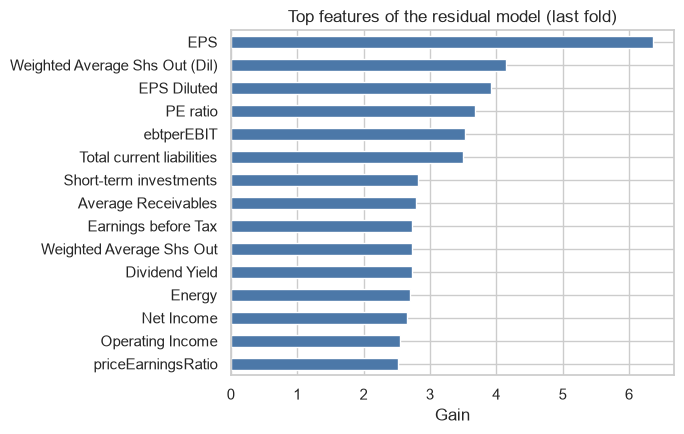

In [9]:
imp = pd.Series(last_model.get_booster().get_score(importance_type="gain")).rename(lambda k: X.columns[int(k[1:])])
imp = imp.sort_values().tail(15)
ax = imp.plot.barh(figsize=(7, 4.5), color="#4c78a8")
ax.set_xlabel("Gain"); ax.set_title("Top features of the residual model (last fold)")
plt.tight_layout(); plt.savefig("figures/04_residual_model_features.png", dpi=150); plt.show()

## 5. What this does and does not show

**Findings** (walk-forward, test years 2016-2018, so returns for 2017-2019)

* **Boosting does not beat the linear model.** Mean rank IC: ridge 0.184, ridge + boosting 0.180, boosting alone 0.173. Stacking did not improve on ridge alone.
* **No consistent evidence of nonlinear signal.** The residual boosting model does correlate with what ridge missed (0.08-0.18), but a *linear* second stage correlates just as well (0.07-0.17), and which one wins flips between years (boosting is better in 2018, linear in 2016, a tie in 2017). The ridge penalty selected is very large, which leaves linear signal in the residuals; that is the most likely thing both second stages pick up.
* **Where the signal lives.** It is concentrated in small caps (mean IC 0.30) and loss-making companies (0.24). Excluding the smallest third by market cap cuts the IC to 0.07, and the top-minus-bottom quintile spread in median next-year return falls from 14 / 24 / 39 points to -1 / 9 / 17.

**Caveats, stated plainly**

* **Three test years.** Each IC is one noisy draw, so these results cannot establish statistical significance across years.
* **The IC level is not believable as tradeable alpha.** Real-world cross-sectional ICs are typically 0.02-0.05; 0.18 here points to something structural. The universe is full of micro-cap and distressed stocks, and the dataset has no filing dates. If year-*Y* statements are filed in early *Y+1*, part of the return window may precede the filing, which would be look-ahead. This cannot be checked with the data provided.
* **No costs, no delisting returns, no point-in-time prices**, and only five cross-sections (the first fold trains on two years).

**Next steps:** point-in-time fundamentals with filing dates, a longer history, sector-neutral targets, and a size filter applied before modelling rather than after.